# NQCC Hackathon 2025 - Part 1: Tutorial Mode
## Computing Ground State ($T_0$) & First Excited State ($S_1$) of $O_2$ using VQE & VQD

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenBioSim/nqcc-hackathon-2025/blob/main/VQD-O2-hackathon.ipynb)

This notebook implements:
1. **Variational Quantum Eigensolver (VQE)** to find the triplet ground state ($T_0$) energy of molecular oxygen ($O_2$).
2. **Variational Quantum Deflation (VQD)** with a SWAP-test overlap penalty to compute the first singlet excited state ($S_1$) energy.
3. **Vertical Excitation Energy** calculation ($\Delta E = E_{S_1} - E_{T_0} \approx 1.467\text{ eV}$) and verification against exact diagonalization and experimental values.


In [1]:
# Install dependencies when running in Google Colab
import sys
if "google.colab" in sys.modules:
    print("Installing dependencies on Google Colab...")
    !pip install -q pennylane pennylane-lightning jax optax openfermion openfermionpyscf pyscf
    print("Installation complete!")


Installing dependencies on Google Colab...
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
Installation complete!


### Step 1: System and Geometry Setup
We define the $O_2$ molecule with bond length $r = 2.30$ Bohr near its equilibrium geometry, choosing an active space of 2 electrons in 3 spatial orbitals (6 spin-orbitals / qubits).

In [2]:
import pennylane as qml
from pennylane import qchem
import jax
import jax.core
from jax import numpy as jnp
import numpy as np
from functools import partial

# Compatibility patch for JAX >= 0.4.30 and PennyLane
try:
    from jax.extend.core import concrete_or_error
    jax.core.concrete_or_error = concrete_or_error
except (ImportError, AttributeError):
    pass

jax.config.update("jax_enable_x64", True)  # float64: avoids complex64 truncation of H

# Active space configuration
active_electrons = 2
active_orbitals = 3

symbols = ["O", "O"]
r = 2.30  # Bond length in Bohr
coordinates = jnp.array([[0.0, 0.0, 0.0], [0.0, 0.0, r]])


### Step 2: Build Molecular Hamiltonian using OpenFermion / PySCF

In [3]:
import pyscf
from pyscf import scf, mp, ci, cc, fci

In [4]:
molecule = qchem.Molecule(symbols, coordinates)
H, qubits = qchem.molecular_hamiltonian(
    molecule,
    active_electrons=active_electrons,
    active_orbitals=active_orbitals,
    method="openfermion"
)
print(f"Hamiltonian terms: {len(H)}, Number of qubits: {qubits}")


Hamiltonian terms: 34, Number of qubits: 6


The Hamiltonian has 34 Pauli strings, but which Pauli terms have the biggest coefficients?



### Step 3: Initial State Preparation & Excitations (UCCSD Ansatz)

In [5]:
# Unpack coefficients and operators using H.terms()
coeffs, ops = H.terms()

# Sort terms by absolute coefficient magnitude
sorted_terms = sorted(zip(coeffs, ops), key=lambda x: abs(x[0]), reverse=True)

print("--- Top 5 Dominant Hamiltonian Terms ---")
for coeff, op in sorted_terms[:5]:
    print(f"Coeff: {float(coeff):+10.4f}  |  Operator: {op}")

--- Top 5 Dominant Hamiltonian Terms ---
Coeff:  -146.3758  |  Operator: I()
Coeff:    -0.5574  |  Operator: Z(4)
Coeff:    -0.5574  |  Operator: Z(5)
Coeff:    -0.2807  |  Operator: Z(0)
Coeff:    -0.2807  |  Operator: Z(1)


In [6]:
coeffs, ops = H.terms()
sorted_terms = sorted(zip(coeffs, ops), key=lambda x:abs(x[0]), reverse=True)
for coeff, op in sorted_terms[:5]:
  print (coeff, op)

-146.37580154843232 I()
-0.5574014098608884 Z(4)
-0.5574014098608883 Z(5)
-0.2807263344945041 Z(0)
-0.2807263344945041 Z(1)


In [7]:
from pennylane import AllSinglesDoubles

singles, doubles = qchem.excitations(active_electrons, qubits)
hf = qchem.hf_state(active_electrons, qubits)
init_state = hf
n_params = len(singles) + len(doubles)

print("Hartree-Fock state:", hf)
print("Singles excitations:", singles)
print("Doubles excitations:", doubles)
print(f"Total ansatz parameters: {n_params}")

try:
    dev = qml.device("lightning.qubit", wires=qubits)
except Exception:
    dev = qml.device("default.qubit", wires=qubits)

@qml.qnode(dev, interface="jax")
def circuit(parameters):
    AllSinglesDoubles(parameters, range(qubits), init_state, singles, doubles)
    return qml.expval(H)


Hartree-Fock state: [1 1 0 0 0 0]
Singles excitations: [[0, 2], [0, 4], [1, 3], [1, 5]]
Doubles excitations: [[0, 1, 2, 3], [0, 1, 2, 5], [0, 1, 3, 4], [0, 1, 4, 5]]
Total ansatz parameters: 8


Wire allocations: 6
Total gates: 1
Gate counts:
- AllSinglesDoubles: 1
Measurements:
- expval(Sum(num_wires=6, num_terms=34)): 1
Depth: 1


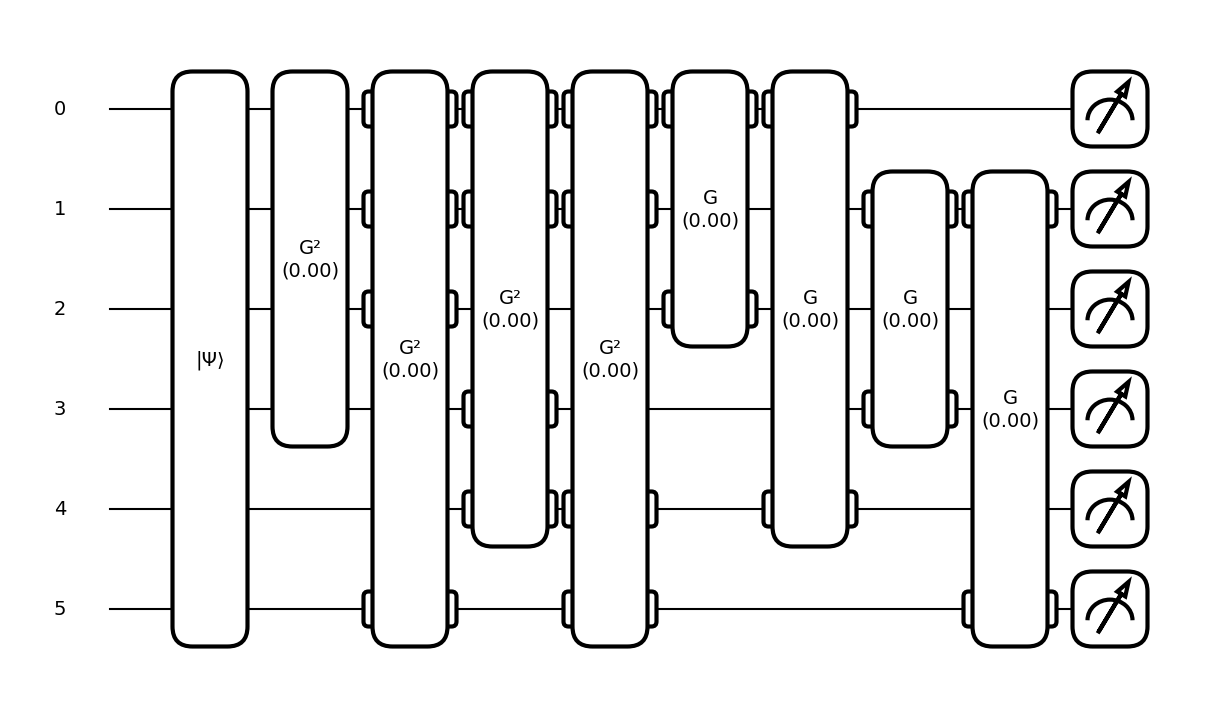

In [8]:
import matplotlib.pyplot as plt
specs = qml.specs(circuit)(np.zeros(n_params))
print(specs["resources"])


@qml.qnode(dev)
def get_initial_state():
    qml.BasisState(hf, wires=range(qubits))
    return qml.state()
decomp_circuit = qml.transforms.decompose(circuit, max_expansion=1)
fig,ax = qml.draw_mpl(decomp_circuit, decimals=2)(np.zeros(n_params))
plt.show()

Here, to visualise the circuit, we see that there is 6 qubits (horizontal line) representing the spin orbitals. While there is 8 G operations, each gate has one angle $\theta$ giving a total of 8 params.  

The left box $|{\Psi}\rangle$ prepares the reference HF state as $|110000\rangle$

### Step 4: Ground State VQE Optimization ($T_0$ Triplet)

In [9]:
import optax

# Optimizer
opt = optax.sgd(learning_rate=0.8) # optax is DeepMind's optimization lib for JAX

# Initialize random gate parameters
np.random.seed(42)
init_vals = np.random.rand(n_params)
init_params = jnp.array(init_vals)

def update_step(params, opt_state):
    grads = jax.grad(circuit)(params)
    updates, opt_state = opt.update(grads, opt_state)
    params = optax.apply_updates(params, updates)
    return params, opt_state

opt_state = opt.init(init_params)
params = init_params
energy = 0.0
prev_energy = energy

print("Running VQE Ground State Optimization...")
for i in range(101):
    energy = float(circuit(params))
    if i % 10 == 0:
        print(f"Step {i:3d}: Energy = {energy:.8f} Ha")

    if abs(energy - prev_energy) < 1e-6 and i > 0:
        print(f"--> Converged at step {i}!")
        break
    prev_energy = energy

    params, opt_state = update_step(params, opt_state)


ground_state_energy = energy
ground_state_params = params
print(ground_state_params)
print(f"\nFinal Ground State Energy (T0): {ground_state_energy:.8f} Ha")

Running VQE Ground State Optimization...
Step   0: Energy = -147.35560453 Ha
Step  10: Energy = -147.57414199 Ha
Step  20: Energy = -147.59781322 Ha
Step  30: Energy = -147.61226857 Ha
Step  40: Energy = -147.62212589 Ha
Step  50: Energy = -147.62763347 Ha
Step  60: Energy = -147.63030352 Ha
Step  70: Energy = -147.63150440 Ha
Step  80: Energy = -147.63202613 Ha
Step  90: Energy = -147.63224946 Ha
Step 100: Energy = -147.63234449 Ha
[1.33351554e+00 3.83476530e-04 1.75882844e+00 1.52695108e-03
 1.53569077e+00 1.47535282e-03 3.83230287e-04 3.05720944e-03]

Final Ground State Energy (T0): -147.63234449 Ha


### Step 5: Verify Ground State Spin $\langle S^2 \rangle$
For a triplet state ($S=1$), the expected value is $\langle S^2 \rangle = S(S+1) = 2$.

In [10]:
S2 = qchem.spin2(active_electrons, qubits)
@qml.qnode(dev, interface="jax")
def S2_exp_value(parameters):
    AllSinglesDoubles(parameters, range(qubits), init_state, singles, doubles)
    return qml.expval(S2)

s2_gs = float(S2_exp_value(ground_state_params))
print(f"Ground state <S^2> = {s2_gs:.4f} (Expected ~2.0 for Triplet T0)")


Ground state <S^2> = 1.9982 (Expected ~2.0 for Triplet T0)


### Step 6: Define Parameterized Ansatz for Excited State Search

In [11]:
@partial(qml.transforms.decompose, max_expansion=1)
def ansatz(theta, wires):
    s_mapped = [[wires[i] for i in single] for single in singles]
    d_mapped = [[wires[i] for i in double] for double in doubles]
    AllSinglesDoubles(theta, wires, hf, s_mapped, d_mapped)

theta_sample = np.random.rand(n_params)
print(qml.draw(ansatz, decimals=2)(theta_sample, range(qubits)))


0: ─╭|Ψ⟩─╭G²(0.83)─╭G²(0.21)─╭G²(0.18)─╭G²(0.18)─╭G(0.60)─╭G(0.71)───────────────────┤  
1: ─├|Ψ⟩─├G²(0.83)─├G²(0.21)─├G²(0.18)─├G²(0.18)─│────────│────────╭G(0.02)─╭G(0.97)─┤  
2: ─├|Ψ⟩─├G²(0.83)─├G²(0.21)─│─────────│─────────╰G(0.60)─│────────│────────│────────┤  
3: ─├|Ψ⟩─╰G²(0.83)─│─────────├G²(0.18)─│──────────────────│────────╰G(0.02)─│────────┤  
4: ─├|Ψ⟩───────────│─────────╰G²(0.18)─├G²(0.18)──────────╰G(0.71)──────────│────────┤  
5: ─╰|Ψ⟩───────────╰G²(0.21)───────────╰G²(0.18)────────────────────────────╰G(0.97)─┤  



## Task 2:  Variational Quantum Deflation (VQD) with  destructive SWAP Test
### Step 7
To find the excited state orthogonal to the ground state, we optimize:
$$\mathcal{L}(\theta) = \langle \psi(\theta) | H | \psi(\theta) \rangle + \beta |\langle \psi(\theta) | \psi_{\text{GS}} \rangle|^2$$
where the overlap is measured with a SWAP test circuit on an ancilla qubit.

Overlap using Destructive SWAP Test: 0.0538


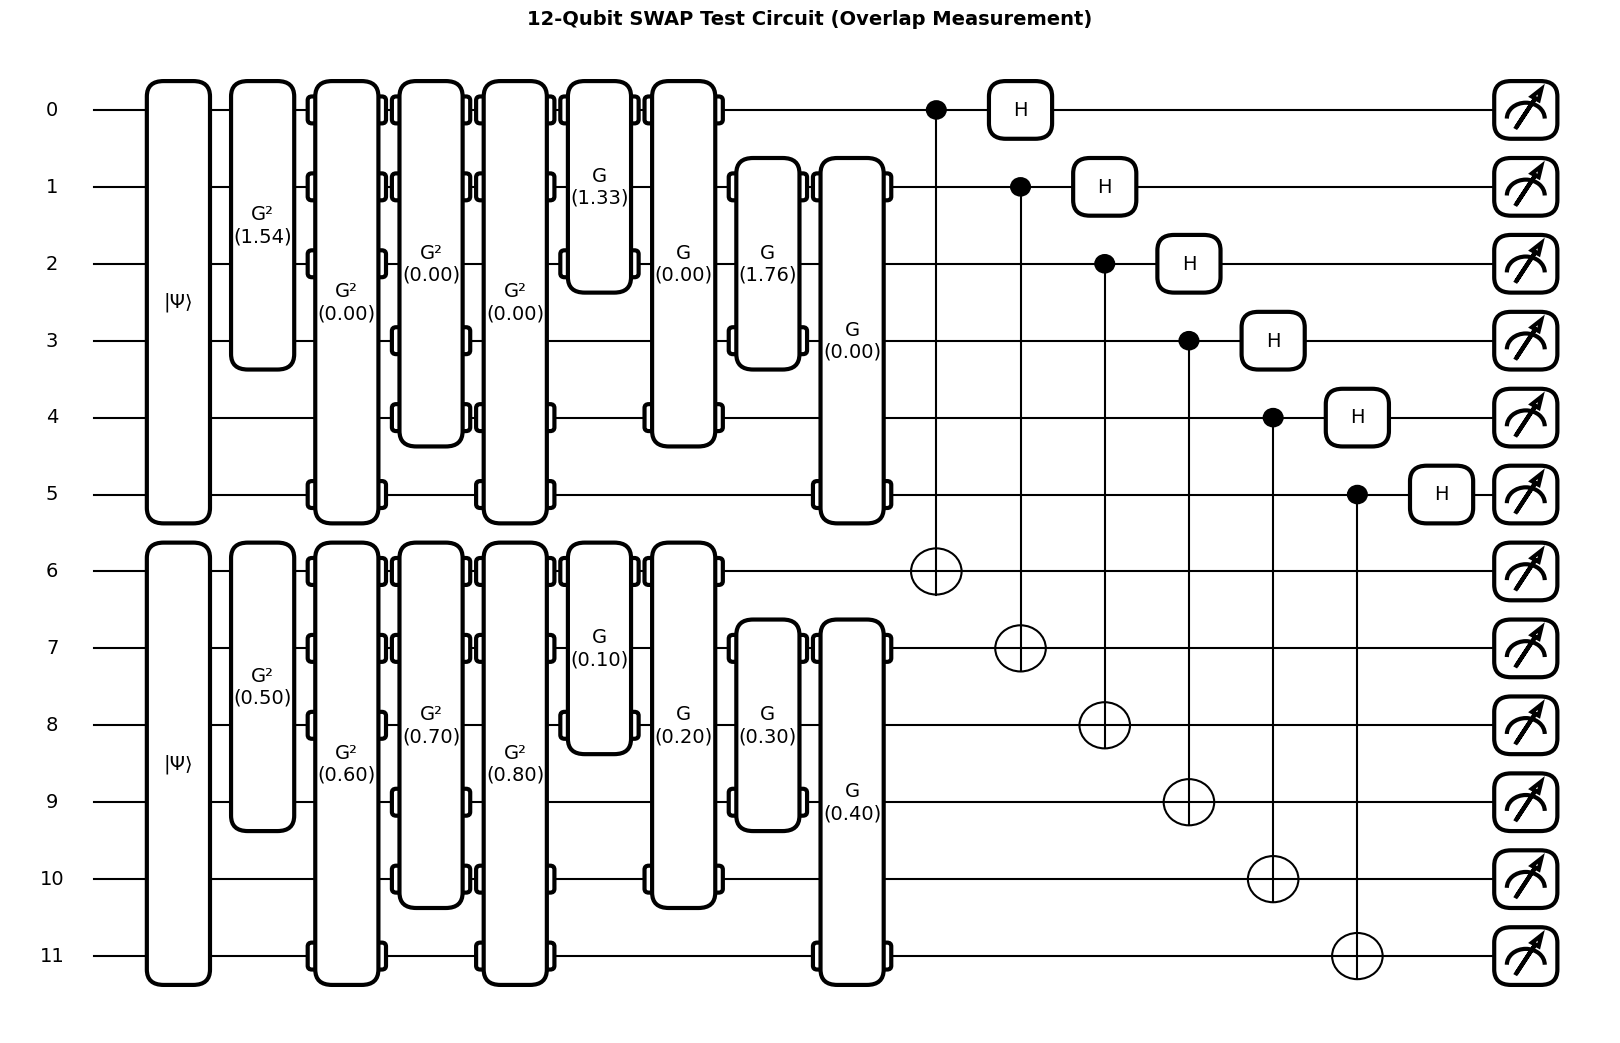

In [12]:
# First precompute the parity operation
n_wires = 2* qubits # This is 12 wires
parities=  np.zeros(2**n_wires) # This is an array of 4096 zeros

for k in range(2**n_wires):
  p=1
  for i in range(qubits):
    a_i = (k >> (2* qubits -1 -i)) & 1
    b_i = (k >> (qubits -1 -i)) & 1
    if a_i == 1 and b_i == 1:
      p *=-1
  parities[k] = p
parity_vector = jnp.array(parities)

try:
  dev_test = qml.device("lightning.qubit", wires=2*qubits)
except Exception:
  dev_test = qml.device("default,qubit", wires=2*qubits)

@qml.qnode(dev_test, interface="jax")
def destructive_swap_circuit(params):
   # Molecule 1 (Ground State) on Wires 0 to 5
   ansatz(ground_state_params, range(qubits))
   # Molecule 2 (Trial Excited State) on Wires 6 to 11
   ansatz(params, range(qubits, 2 * qubits))

   for i in range(qubits):
    qml.CNOT(wires=[i, i + qubits])
    qml.Hadamard(wires=i)
   return qml.probs(wires=range(2 * qubits))


def swap_test(params):
  probs = destructive_swap_circuit(params)
  return jnp.dot(parity_vector, probs)
dev_energy = qml.device("lightning.qubit", wires=qubits)

@qml.qnode(dev_energy, interface="jax")
def expected_value(theta):
  ansatz(theta, range(qubits)) #prepare anstaz ES
  return qml.expval(H) # returns the energy of this trial state

def loss_f(theta, beta):
  return expected_value(theta) + beta * swap_test(theta)
init_theta = jnp.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8])
print(
    f"Overlap using Destructive SWAP Test: {float(swap_test(init_theta)):.4f}"
)

import matplotlib.pyplot as plt
fig, ax = qml.draw_mpl(destructive_swap_circuit, decimals=2)(init_theta)
fig.set_size_inches(16, 10)
plt.title(
    "12-Qubit SWAP Test Circuit (Overlap Measurement)",
    fontsize=14,
    fontweight="bold",
)
plt.show()



In [13]:
decomp_dest = qml.transforms.decompose(
    destructive_swap_circuit, max_expansion=3
)
specs_dest = qml.specs(decomp_dest)(init_theta)
resources = specs_dest["resources"]

cnot_count = resources.gate_types.get("CNOT")
total_gates = resources.num_gates


print(f"Total gates in the destructive SWAP test circuit: {total_gates}")
print(f"CNOT gates in the destructive SWAP test circuit: {cnot_count}")

Total gates in the destructive SWAP test circuit: 30
CNOT gates in the destructive SWAP test circuit: 6


### Step 8: Optimize First Excited State ($S_1$ Singlet)

In [14]:
theta = jnp.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8])
beta = 2.0
opt_vqd = optax.sgd(learning_rate=0.4)
opt_state = opt_vqd.init(theta)

energy_history = [float(loss_f(theta, beta))]
conv_tol = 1e-6
max_iterations = 100

for n in range(max_iterations):
    gradient = jax.grad(loss_f)(theta, beta)
    updates, opt_state = opt_vqd.update(gradient, opt_state)
    theta = optax.apply_updates(theta, updates)
    current_loss = float(loss_f(theta, beta))
    energy_history.append(current_loss)

    if n % 10 == 0:
        print(f"Step {n:3d}: Loss = {current_loss:.8f} Ha, Energy = {float(expected_value(theta)):.8f} Ha, Overlap = {float(swap_test(theta)):.5f}")

    if abs(energy_history[-1] - energy_history[-2]) < conv_tol:
        print(f"Converged at step {n}!")
        break

excited_energy = float(expected_value(theta))
print(f"\nEstimated Excited State Energy (S1): {excited_energy:.8f} Ha")
print(theta)

Step   0: Loss = -147.37620395 Ha, Energy = -147.41239628 Ha, Overlap = 0.01810
Step  10: Loss = -147.54280973 Ha, Energy = -147.54283447 Ha, Overlap = 0.00001
Step  20: Loss = -147.56489817 Ha, Energy = -147.56490286 Ha, Overlap = 0.00000
Step  30: Loss = -147.57041465 Ha, Energy = -147.57041679 Ha, Overlap = 0.00000
Step  40: Loss = -147.57246965 Ha, Energy = -147.57247134 Ha, Overlap = 0.00000
Step  50: Loss = -147.57363672 Ha, Energy = -147.57363829 Ha, Overlap = 0.00000
Step  60: Loss = -147.57449379 Ha, Energy = -147.57449529 Ha, Overlap = 0.00000
Step  70: Loss = -147.57518576 Ha, Energy = -147.57518720 Ha, Overlap = 0.00000
Step  80: Loss = -147.57575931 Ha, Energy = -147.57576071 Ha, Overlap = 0.00000
Step  90: Loss = -147.57623713 Ha, Energy = -147.57623849 Ha, Overlap = 0.00000

Estimated Excited State Energy (S1): -147.57659967 Ha
[-1.66009245e-01  5.96981146e-06  1.08048682e-01  4.56797495e-04
  1.17439180e+00  8.98250517e-04  8.97826697e-04  2.77707648e-02]


### Step 9: Verify Excited State Spin $\langle S^2 \rangle$
For a singlet state ($S=0$), the expected value is $\langle S^2 \rangle = 0$.

In [15]:
s2_es = float(S2_exp_value(theta))
print(f"Excited state <S^2> = {s2_es:.4f} (Expected ~0.0 for Singlet S1)")


Excited state <S^2> = 0.0016 (Expected ~0.0 for Singlet S1)


### Step 10: Vertical Excitation Energy & Benchmark Comparison

In [16]:
# Conversion factor: 1 Hartree = 27.2114 eV
HA_TO_EV = 27.2114

delta_E_ha = excited_energy - ground_state_energy
delta_E_ev = delta_E_ha * HA_TO_EV

# Exact diagonalisation of H
H_mat = qml.matrix(H)
exact_eigs = np.sort(np.linalg.eigvalsh(H_mat))
exact_gs = exact_eigs[0]
exact_es = exact_eigs[3]  # First distinct singlet eigenvalue
exact_delta_ha = exact_es - exact_gs
exact_delta_ev = exact_delta_ha * HA_TO_EV

print("=" * 60)
print("          TUTORIAL MODE - FINAL RESULTS SUMMARY")
print("=" * 60)
print(f"Ground State (T0 Triplet) Energy:   {ground_state_energy:.8f} Ha  (<S^2>={s2_gs:.3f})")
print(f"Excited State (S1 Singlet) Energy:  {excited_energy:.8f} Ha  (<S^2>={s2_es:.3f})")
print(f"Energy Difference (Delta E):        {delta_E_ha:.8f} Ha")
print(f"VQD Vertical Excitation Energy:     {delta_E_ev:.4f} eV")
print(f"Exact Vertical Excitation Energy:   {exact_delta_ev:.4f} eV")
print("-" * 60)
print("Benchmark Comparison Table:")
print("  Method            Excitation Energy (eV)")
print(f"  Your VQD run:     {delta_E_ev:.3f} eV")
print(f"  Exact in subspace:{exact_delta_ev:.3f} eV  (ca. 1.467 eV)")
print("  CCSD(T)/STO-3G:   1.334 eV")
print("  HF/STO-3G:        2.278 eV")
print("  Experiment:       0.980 eV")
print("=" * 60)


          TUTORIAL MODE - FINAL RESULTS SUMMARY
Ground State (T0 Triplet) Energy:   -147.63234449 Ha  (<S^2>=1.998)
Excited State (S1 Singlet) Energy:  -147.57659967 Ha  (<S^2>=0.002)
Energy Difference (Delta E):        0.05574482 Ha
VQD Vertical Excitation Energy:     1.5169 eV
Exact Vertical Excitation Energy:   1.4675 eV
------------------------------------------------------------
Benchmark Comparison Table:
  Method            Excitation Energy (eV)
  Your VQD run:     1.517 eV
  Exact in subspace:1.467 eV  (ca. 1.467 eV)
  CCSD(T)/STO-3G:   1.334 eV
  HF/STO-3G:        2.278 eV
  Experiment:       0.980 eV


The HF/STO-3G: gives 2.278eV. this is the simplest classical result, which ignores electron correlationi (they only feel an average cloud). This is the worst method yet because it doesn't allow electrons to correlate and avoid each other.  

Exact in subspace (1.467 eV): This is the mathematical limit i.e. bruteforce diagonalising the matrix.  

CCSD(T) / STO-3G (1.334 eV): Coupled Cluster with Singles, Doubles, and perturbative Triples. This is the most accurate classical algorithm chemists use.

Overlap using Destructive SWAP Test: 0.0538


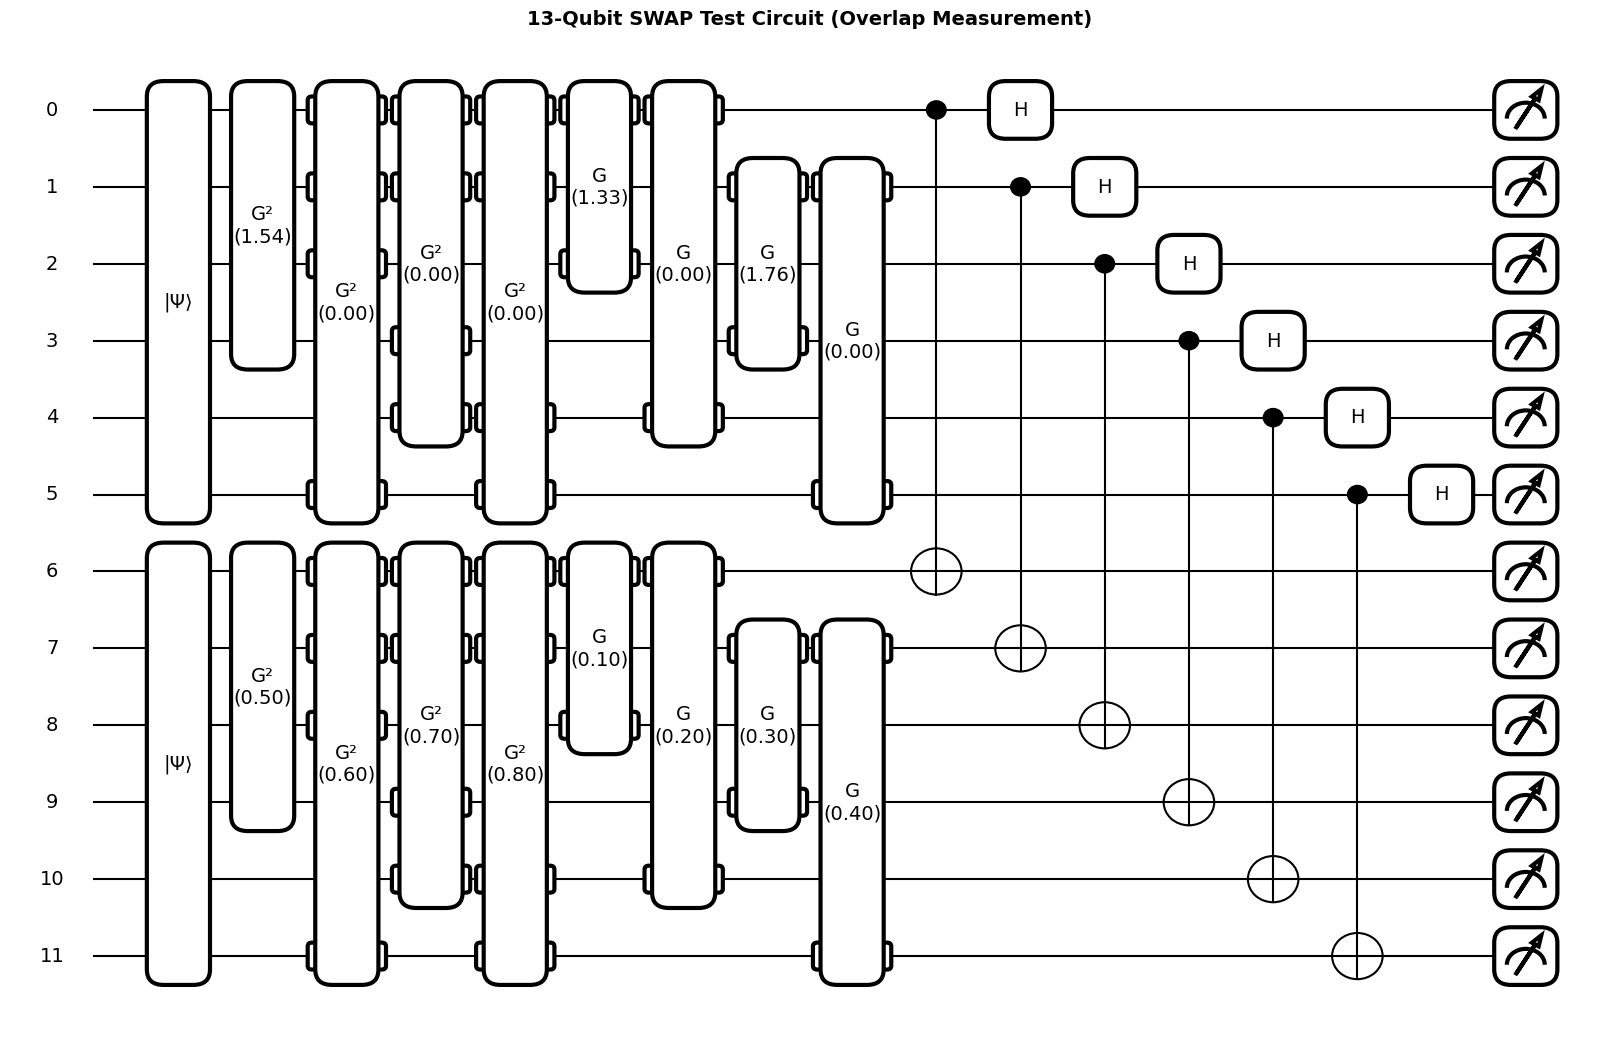

In [17]:
# First precompute the parity operation
n_wires = 2* qubits # This is 12 wires
parities=  np.zeros(2**n_wires) # This is an array of 4096 zeros

for k in range(2**n_wires):
  p=1
  for i in range(qubits):
    a_i = (k >> (2* qubits -1 -i)) & 1
    b_i = (k >> (qubits -1 -i)) & 1
    if a_i == 1 and b_i == 1:
      p *=-1
  parities[k] = p
parity_vector = jnp.array(parities)

try:
  dev_test = qml.device("lightning.qubit", wires=2*qubits)
except Exception:
  dev_test = qml.device("default,qubit", wires=2*qubits)

@qml.qnode(dev_test, interface="jax")
def destructive_swap_circuit(params):
   # Molecule 1 (Ground State) on Wires 0 to 5
   ansatz(ground_state_params, range(qubits))
   # Molecule 2 (Trial Excited State) on Wires 6 to 11
   ansatz(params, range(qubits, 2 * qubits))

   for i in range(qubits):
    qml.CNOT(wires=[i, i + qubits])
    qml.Hadamard(wires=i)
   return qml.probs(wires=range(2 * qubits))


def swap_test(params):
  probs = destructive_swap_circuit(params)
  return jnp.dot(parity_vector, probs)
dev_energy = qml.device("lightning.qubit", wires=qubits)

@qml.qnode(dev_energy, interface="jax")
def expected_value(theta):
  ansatz(theta, range(qubits))
  return qml.expval(H)

def loss_f(theta, beta):
  return expected_value(theta) + beta * swap_test(theta)
init_theta = jnp.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8])
print(
    f"Overlap using Destructive SWAP Test: {float(swap_test(init_theta)):.4f}"
)

import matplotlib.pyplot as plt
fig, ax = qml.draw_mpl(destructive_swap_circuit, decimals=2)(init_theta)
fig.set_size_inches(16, 10)
plt.title(
    "13-Qubit SWAP Test Circuit (Overlap Measurement)",
    fontsize=14,
    fontweight="bold",
)
plt.show()



In [18]:
# Ensure real coefficients and standard Hamiltonian representation
coeffs, ops = H.terms()
H_clean = qml.Hamiltonian(np.real(coeffs), ops)
print(H_clean)

-146.37580154843232 * I() + -0.2807263344945041 * Z(0) + -0.2807263344945041 * Z(1) + -0.2807263344945036 * Z(2) + -0.2807263344945036 * Z(3) + -0.5574014098608884 * Z(4) + -0.5574014098608883 * Z(5) + 0.16321987463642723 * (Z(0) @ Z(1)) + 0.006740996781440558 * (Y(0) @ X(1) @ X(2) @ Y(3)) + -0.006740996781440558 * (Y(0) @ Y(1) @ X(2) @ X(3)) + -0.006740996781440558 * (X(0) @ X(1) @ Y(2) @ Y(3)) + 0.006740996781440558 * (X(0) @ Y(1) @ Y(2) @ X(3)) + 0.01013614870305241 * (Y(0) @ X(1) @ X(4) @ Y(5)) + -0.01013614870305241 * (Y(0) @ Y(1) @ X(4) @ X(5)) + -0.01013614870305241 * (X(0) @ X(1) @ Y(4) @ Y(5)) + 0.01013614870305241 * (X(0) @ Y(1) @ Y(4) @ X(5)) + 0.1429968842921056 * (Z(0) @ Z(2)) + 0.14973788107354616 * (Z(0) @ Z(3)) + 0.15374880130413834 * (Z(0) @ Z(4)) + 0.16388495000719075 * (Z(0) @ Z(5)) + 0.14973788107354616 * (Z(1) @ Z(2)) + 0.1429968842921056 * (Z(1) @ Z(3)) + 0.16388495000719075 * (Z(1) @ Z(4)) + 0.15374880130413834 * (Z(1) @ Z(5)) + 0.1632198746364274 * (Z(2) @ Z(3))

In [19]:
import pennylane as qml
from pennylane import qchem
import numpy as np
import itertools


# Find Z2 symmetry generators
generators = qml.symmetry_generators(H_clean)
print(f"\n1. Found {len(generators)} Symmetry Generators (tau):")
for i, g in enumerate(generators):
    print(f"   tau_{i}: {g}")

if len(generators) == 0:
    print("No Z2 symmetries found for this Hamiltonian.")
else:
    #Find single-qubit Pauli-X operators to eliminate
    paulixops = qml.paulix_ops(generators, qubits)
    print(f"\n2. Pauli-X operators (wires to be tapered):")
    for i, px in enumerate(paulixops):
        print(f"   tau_{i} -> eliminate wire {px.wires[0]} via {px}")

    #Determine optimal sector
    try:
        sec_hf = qchem.optimal_sector(H_clean, generators, active_electrons)
        print(f"\n3. PennyLane optimal_sector (Hartree-Fock reference): {sec_hf}")
    except Exception as e:
        print(f"\n3. PennyLane optimal_sector note: {e}")
        sec_hf = None

    #Systematically scan all 2^k sectors by exact diagonalization
    all_sectors = list(itertools.product([1, -1], repeat=len(generators)))
    print(f"\n4. Scanning all {len(all_sectors)} eigenvalue sectors to find true ground state:")

    best_sector = None
    min_energy = float("inf")

    for s in all_sectors:
        s_list = list(s)
        H_t = qml.taper(H_clean, generators, paulixops, s_list)
        eig_val = np.linalg.eigvalsh(qml.matrix(H_t))[0]
        if eig_val < min_energy:
            min_energy = eig_val
            best_sector = s_list
        print(f"   Sector {s_list}: Ground State Energy = {eig_val:.6f} Ha")

    print(f"\nOptimal Ground-State Sector: {best_sector} with E = {min_energy:.6f} Ha")

    #Taper Hamiltonian with the optimal ground-state sector
    H_tapered = qml.taper(H_clean, generators, paulixops, best_sector)
    print(H_tapered)
    t_coeffs, t_ops = H_tapered.terms()
    print(f"\n5. Tapering Summary:")
    print(f"   Original qubits: {qubits} (terms: {len(H_clean)})")
    print(f"   Tapered qubits:  {len(H_tapered.wires)} (wires: {list(H_tapered.wires)})")
    print(f"   Tapered terms:   {len(t_ops)}")
    print(f"   Exact energy preserved: {np.isclose(min_energy, -147.63229, atol=1e-4)}")


1. Found 4 Symmetry Generators (tau):
   tau_0: Z(0) @ Z(1)
   tau_1: Z(2) @ Z(3)
   tau_2: Z(0) @ Z(2) @ Z(4)
   tau_3: Z(0) @ Z(2) @ Z(5)

2. Pauli-X operators (wires to be tapered):
   tau_0 -> eliminate wire 1 via X(1)
   tau_1 -> eliminate wire 3 via X(3)
   tau_2 -> eliminate wire 4 via X(4)
   tau_3 -> eliminate wire 5 via X(5)

3. PennyLane optimal_sector (Hartree-Fock reference): [1, 1, -1, -1]

4. Scanning all 16 eigenvalue sectors to find true ground state:
   Sector [1, 1, 1, 1]: Ground State Energy = -146.530873 Ha
   Sector [1, 1, 1, -1]: Ground State Energy = -146.859907 Ha
   Sector [1, 1, -1, 1]: Ground State Energy = -146.859907 Ha
   Sector [1, 1, -1, -1]: Ground State Energy = -147.578487 Ha
   Sector [1, -1, 1, 1]: Ground State Energy = -147.367791 Ha
   Sector [1, -1, 1, -1]: Ground State Energy = -147.155638 Ha
   Sector [1, -1, -1, 1]: Ground State Energy = -147.155638 Ha
   Sector [1, -1, -1, -1]: Ground State Energy = -147.367791 Ha
   Sector [-1, 1, 1, 1]: G

In [20]:
eigenvalues = np.linalg.eigvalsh(qml.matrix(H_tapered))
for i, E in enumerate(eigenvalues):
    print(f"Eigenvalue {i}: {E:.6f} Ha")
    

Eigenvalue 0: -147.632415 Ha
Eigenvalue 1: -147.632415 Ha
Eigenvalue 2: -145.402809 Ha
Eigenvalue 3: -145.348881 Ha


The energy of ES is not in the Hamiltonian because they don't belong to the same sector. Because the two states have different spin orientations, they have different eigenvalues under the spin parity symmetry $\tau$

In the reduced 2 qubit 4x4 Hamiltonian, these are the eigenvalues. The first 2 are identical up to 6 decimals, because the ground state s a triplet $S=1$ so it is degenerate in spatial orbitals. One corresponds to placing the electrons along x, the other along y. Due to symmetry both have the exact same energy

Sector [1, 1, -1, -1] -> Lowest Energy: -147.578487 Ha  
Sector [-1, -1, 1, 1]: Ground State Energy = -147.632415 Ha  
$\Delta E = E(S_1) - E(T_0)$ = -147.578487 - (-147.632415)=+0.053928 Ha = 1.4675eV

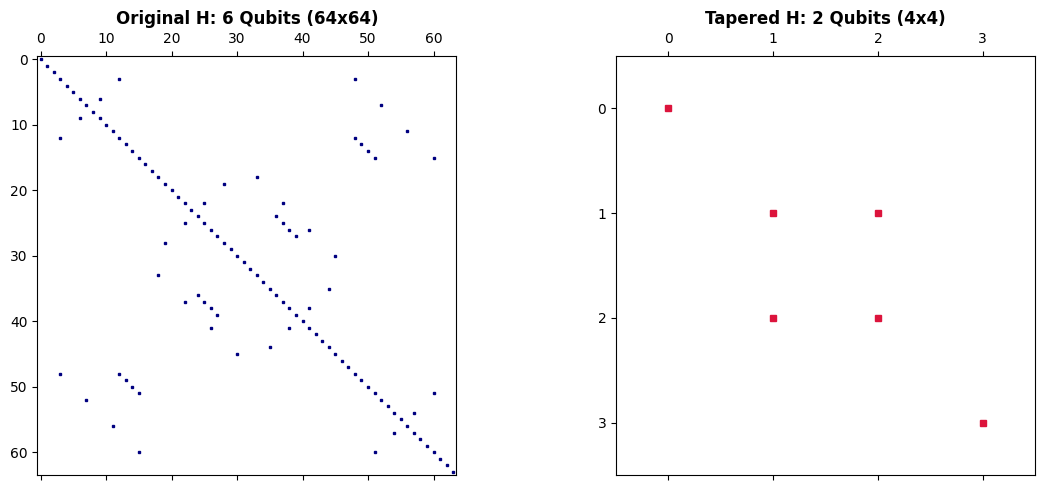

In [21]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Original 6-qubit matrix (64 x 64)
mat_orig = qml.matrix(H_clean)
ax1.spy(mat_orig, markersize=2, color="navy")
ax1.set_title(f"Original H: 6 Qubits ({mat_orig.shape[0]}x{mat_orig.shape[1]})", fontweight="bold")

# Tapered 4-qubit matrix (16 x 16)
mat_tapered = qml.matrix(H_tapered)
ax2.spy(mat_tapered, markersize=5, color="crimson")
ax2.set_title(f"Tapered H: 2 Qubits ({mat_tapered.shape[0]}x{mat_tapered.shape[1]})", fontweight="bold")

plt.tight_layout()
plt.show()

---
# Task 2: 2-Qubit Tapered VQE Execution 
Having verified through classical diagonalization that:
- **Triplet Ground State ($T_0$)** lives in Sector `[-1, -1, 1, 1]` with $E = -147.632415\text{ Ha}$
- **Singlet Excited State ($S_1$)** lives in Sector `[1, 1, -1, -1]` with $E = -147.578487\text{ Ha}$

We now execute the hybrid quantum-classical VQE algorithm on the reduced 2-qubit quantum system for both sectors.

Because $T_0$ and $S_1$ live in different symmetry sectors, they are strictly orthogonal by symmetry ($\langle T_0 | S_1 \rangle = 0$).
Therefore, no SWAP test or VQD overlap penalty is required! We simply solve two independent, extremely compact 2-qubit VQE circuits.

Surviving active wires: [0, 1] -> remapped to [0, 1]
H_2q (Triplet T0): 4 terms, exact GS -147.632415 Ha
H_2q (Singlet S1): 10 terms, exact GS -147.578487 Ha

=== 2-Qubit Variational Quantum Circuit ===
0: ──RY(0.00)──RZ(0.00)─╭●──RY(0.00)──RZ(0.00)─┤  
1: ──RY(0.00)──RZ(0.00)─╰X──RY(0.00)──RZ(0.00)─┤  

--- Running 2-Qubit VQE for Triplet Ground State (T0) ---
  restart 0: E = -147.63238972 Ha after 100 steps
  restart 1: E = -147.63218344 Ha after 75 steps
  restart 2: E = -147.63225034 Ha after 96 steps
  restart 3: E = -147.63226991 Ha after 61 steps

--- Running 2-Qubit VQE for Singlet Excited State (S1) ---
  restart 0: E = -147.57644376 Ha after 100 steps
  restart 1: E = -147.57825114 Ha after 100 steps
  restart 2: E = -147.55648233 Ha after 100 steps
  restart 3: E = -147.55825207 Ha after 100 steps
[ 4.72088452  3.15168806 -0.02399731 -0.28146557  4.26526778  4.8850912
  4.26612921  5.43348331]
[ 4.73429763  6.19911311  5.89451096  1.34256561  4.91776318 -0.93224389
  4.4841

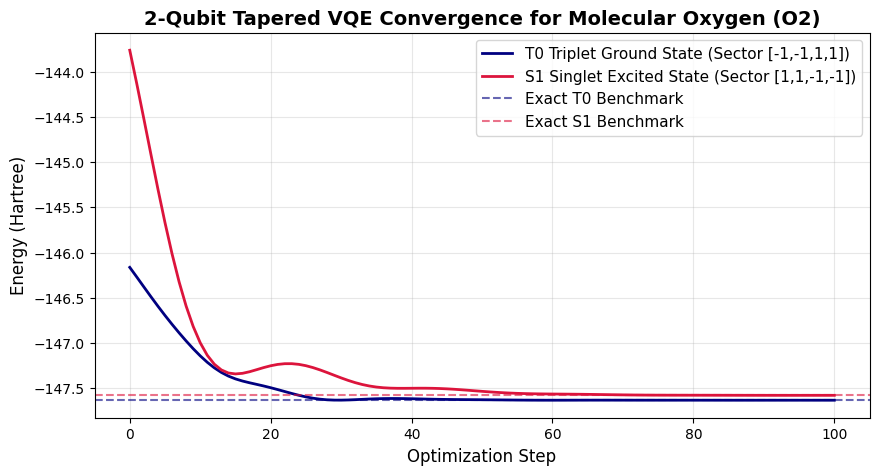

In [26]:
import pennylane as qml
import jax
jax.config.update("jax_enable_x64", True)
from jax import numpy as jnp
import numpy as np
import optax
import matplotlib.pyplot as plt

# 1. Extract the Tapered Hamiltonians for both sectors
sector_T0 = [-1, -1, 1, 1]   # T0 also appears in [-1, -1, -1, -1]
sector_S1 = [1, 1, -1, -1]

H_tapered_T0 = qml.taper(H_clean, generators, paulixops, sector_T0)
H_tapered_S1 = qml.taper(H_clean, generators, paulixops, sector_S1)

# Cleanly remap surviving wires to standard indices 0 and 1
active_wires = sorted(set(H_tapered_T0.wires) | set(H_tapered_S1.wires))
wire_map = {w: i for i, w in enumerate(active_wires)}
H_2q_T0 = qml.map_wires(H_tapered_T0, wire_map)
H_2q_S1 = qml.map_wires(H_tapered_S1, wire_map)

exact_T0 = np.linalg.eigvalsh(qml.matrix(H_2q_T0, wire_order=[0, 1]))[0]
exact_S1 = np.linalg.eigvalsh(qml.matrix(H_2q_S1, wire_order=[0, 1]))[0]

print(f"Surviving active wires: {active_wires} -> remapped to [0, 1]")
print(f"H_2q (Triplet T0): {len(H_2q_T0.terms()[0])} terms, exact GS {exact_T0:.6f} Ha")
print(f"H_2q (Singlet S1): {len(H_2q_S1.terms()[0])} terms, exact GS {exact_S1:.6f} Ha")

# 2. General 2-qubit ansatz: RY+RZ on each qubit, 1 CNOT, RY+RZ on each qubit.
#    One CNOT is enough to reach ANY 2-qubit state (Schmidt decomposition),
#    including complex amplitudes. 8 parameters.
dev_2q = qml.device("default.qubit", wires=2)
N_PARAMS_2Q = 8

def ansatz_2q(params):
    qml.RY(params[0], wires=0); qml.RZ(params[1], wires=0)
    qml.RY(params[2], wires=1); qml.RZ(params[3], wires=1)
    qml.CNOT(wires=[0, 1])
    qml.RY(params[4], wires=0); qml.RZ(params[5], wires=0)
    qml.RY(params[6], wires=1); qml.RZ(params[7], wires=1)

print("\n=== 2-Qubit Variational Quantum Circuit ===")
print(qml.draw(ansatz_2q)(jnp.zeros(N_PARAMS_2Q)))

# 3. QNodes for energy evaluation
@qml.qnode(dev_2q, interface="jax")
def cost_T0(params):
    ansatz_2q(params)
    return qml.expval(H_2q_T0)

@qml.qnode(dev_2q, interface="jax")
def cost_S1(params):
    ansatz_2q(params)
    return qml.expval(H_2q_S1)

# 4. Adam + random restarts
def run_2q_vqe(cost_fn, name, n_steps=100, lr=0.05, n_restarts=4, seed=0, tol=1e-6):
    print(f"\n--- Running 2-Qubit VQE for {name} ---")
    try:
        opt = optax.adam(lr)
        def step(params, opt_state):
            energy, grads = jax.value_and_grad(cost_fn)(params)
            updates, opt_state = opt.update(grads, opt_state)
            return optax.apply_updates(params, updates), opt_state, energy

        rng = np.random.default_rng(seed)
        best = None
        for r in range(n_restarts):
            params = jnp.array(rng.uniform(0, 2 * np.pi, N_PARAMS_2Q))
            opt_state = opt.init(params)
            history = []
            for it in range(n_steps):
                params, opt_state, energy = step(params, opt_state)
                history.append(float(energy))
                if it > 20 and abs(history[-1] - history[-2]) < tol:
                    break
            final = float(cost_fn(params))
            history.append(final)
            print(f"  restart {r}: E = {final:.8f} Ha after {len(history) - 1} steps")
            if best is None or final < best[0]:
                best = (final, np.array(params), history)
        return best
    except Exception:
        # Fallback to PennyLane Adam if JAX tracing encounters version mismatch
        opt = qml.AdamOptimizer(stepsize=lr)
        rng = np.random.default_rng(seed)
        best = None
        for r in range(n_restarts):
            params = np.array(rng.uniform(0, 2 * np.pi, N_PARAMS_2Q))
            history = []
            for it in range(n_steps):
                params, energy = opt.step_and_cost(cost_fn, params)
                history.append(float(energy))
                if it > 20 and abs(history[-1] - history[-2]) < tol:
                    break
            final = float(cost_fn(params))
            history.append(final)
            print(f"  restart {r}: E = {final:.8f} Ha after {len(history) - 1} steps")
            if best is None or final < best[0]:
                best = (final, np.array(params), history)
        return best

E_T0_vqe, opt_params_T0, hist_T0 = run_2q_vqe(cost_T0, "Triplet Ground State (T0)")
E_S1_vqe, opt_params_S1, hist_S1 = run_2q_vqe(cost_S1, "Singlet Excited State (S1)")
print(opt_params_T0)
print(opt_params_S1)
# 5. Final excitation energy
HA_TO_EV = 27.211386
delta_E_ha = E_S1_vqe - E_T0_vqe
delta_E_ev = delta_E_ha * HA_TO_EV
exact_delta_ev = (exact_S1 - exact_T0) * HA_TO_EV

print("\n" + "=" * 65)
print("             2-QUBIT TAPERED VQE - FINAL RESULTS")
print("=" * 65)
print(f"Ground State (T0 Triplet) Energy:   {E_T0_vqe:.6f} Ha  (error {abs(E_T0_vqe - exact_T0):.1e})")
print(f"Excited State (S1 Singlet) Energy:  {E_S1_vqe:.6f} Ha  (error {abs(E_S1_vqe - exact_S1):.1e})")
print(f"Energy Difference (Delta E):        {delta_E_ha:.6f} Ha")
print(f"2-Qubit VQE Vertical Excitation:    {delta_E_ev:.4f} eV")
print(f"Exact Active-Space Benchmark:       {exact_delta_ev:.4f} eV")
print(f"Error vs. Subspace Limit:           {abs(delta_E_ev - exact_delta_ev) * 1000:.3f} meV")
print("=" * 65)

# 6. Convergence curves (best restart)
plt.figure(figsize=(10, 5))
plt.plot(hist_T0, label="T0 Triplet Ground State (Sector [-1,-1,1,1])", color="navy", lw=2)
plt.plot(hist_S1, label="S1 Singlet Excited State (Sector [1,1,-1,-1])", color="crimson", lw=2)
plt.axhline(exact_T0, color="navy", ls="--", alpha=0.6, label="Exact T0 Benchmark")
plt.axhline(exact_S1, color="crimson", ls="--", alpha=0.6, label="Exact S1 Benchmark")
plt.xlabel("Optimization Step", fontsize=12)
plt.ylabel("Energy (Hartree)", fontsize=12)
plt.title("2-Qubit Tapered VQE Convergence for Molecular Oxygen (O2)", fontsize=14, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Original 6-qubit matrix (64 x 64)
mat_orig = qml.matrix(H_tapered_T0)
ax1.spy(mat_orig, markersize=5, color="navy")
ax1.set_title(f"Ground State H: 2 Qubits ({mat_orig.shape[0]}x{mat_orig.shape[1]})", fontweight="bold")

# Tapered 4-qubit matrix (16 x 16)
mat_tapered = qml.matrix(H_tapered_S1)
ax2.spy(mat_tapered, markersize=5, color="crimson")
ax2.set_title(f"Excited State H: 2 Qubits ({mat_tapered.shape[0]}x{mat_tapered.shape[1]})", fontweight="bold")

plt.tight_layout()
plt.show()

In [27]:
# Print the 4 Pauli terms and their coefficients in the T0 Hamiltonian
coeffs, ops = H_2q_T0.terms()
print("=== The 4 Pauli Terms of the T0 Hamiltonian ===")
for c, op in zip(coeffs, ops):
    print(f"  {float(c):+12.6f} * {op}")

=== The 4 Pauli Terms of the T0 Hamiltonian ===
   -146.504130 * I()
     -1.128285 * Z(0) @ Z(1)
     -0.013482 * Y(0) @ Y(1)
     -0.013482 * X(0) @ X(1)


If the two qubits have positive parity Z0Z1 = +1 then the first two terms give −146.504130−1.128285=−147.632415 Ha which is the CASCi GS eigenvalue

In [ ]:
fig, ax = qml.draw_mpl(ansatz_2q, decimals=2)(opt_params_T0)
fig.set_size_inches(8, 4)
plt.title("2-Qubit Tapered VQE Ansatz Circuit", fontsize=14, fontweight="bold")
plt.show()

---
# Measured gate counts (`qml.specs`)
Every circuit is decomposed to CNOT + single-qubit gates before counting, so the numbers are hardware-level CNOTs (excitation gates and CSWAPs are expanded, not counted as one gate). Copy the printed table into the README.

In [ ]:
from functools import partial
from collections import Counter

GATE_SET = {"CNOT", "RX", "RY", "RZ", "Hadamard", "PauliX", "PauliY", "PauliZ",
            "S", "Adjoint(S)", "T", "Adjoint(T)", "SX", "PhaseShift", "GlobalPhase"}

def uccsd(theta, wires):
    wires = list(wires)
    s = [[wires[i] for i in ex] for ex in singles]
    d = [[wires[i] for i in ex] for ex in doubles]
    AllSinglesDoubles(theta, wires, hf, s, d)

theta0 = np.linspace(0.1, 0.8, n_params)
q = qubits

@qml.qnode(qml.device("default.qubit", wires=q))
def circ_a(theta):                      # (a) baseline 6-qubit VQE
    uccsd(theta, range(q))
    return qml.expval(H_clean)

@qml.qnode(qml.device("default.qubit", wires=2 * q + 1))
def circ_b(theta):                      # (b) 13-qubit CSWAP overlap
    uccsd(theta0, range(1, q + 1))
    uccsd(theta, range(q + 1, 2 * q + 1))
    qml.Hadamard(wires=0)
    for i in range(q):
        qml.CSWAP(wires=[0, 1 + i + q, 1 + i])
    qml.Hadamard(wires=0)
    return qml.expval(qml.Z(0))

@qml.qnode(qml.device("default.qubit", wires=2 * q))
def circ_c(theta):                      # (c) 12-qubit destructive SWAP
    uccsd(theta0, range(q))
    uccsd(theta, range(q, 2 * q))
    for i in range(q):
        qml.CNOT(wires=[i, i + q])
        qml.Hadamard(wires=i)
    return qml.probs(wires=range(2 * q))

@qml.qnode(qml.device("default.qubit", wires=2))
def circ_d(params):                     # (d) 2-qubit tapered VQE
    ansatz_2q(params)
    return qml.expval(H_2q_S1)

rows = [("(a) 6q AllSinglesDoubles VQE", circ_a, theta0, q),
        ("(b) 13q CSWAP overlap",        circ_b, theta0, 2 * q + 1),
        ("(c) 12q destructive SWAP",     circ_c, theta0, 2 * q),
        ("(d) 2q tapered VQE",           circ_d, jnp.linspace(0.1, 0.8, N_PARAMS_2Q), 2)]

print(f"{'Circuit':32s} {'wires':>5s} {'CNOT':>6s} {'total gates':>12s}  depth")
for name, circ, args, wires in rows:
    res = qml.specs(qml.transforms.decompose(circ, gate_set=GATE_SET))(args)["resources"]
    gt = dict(res.gate_types)
    gt.pop("GlobalPhase", None)
    print(f"{name:32s} {wires:5d} {gt.get('CNOT', 0):6d} {sum(gt.values()):12d}  {res.depth}")
    print(f"    {gt}")